In [48]:
from rdkit import Chem
import csv

In [49]:
from pathlib import Path

def process_reaction_files(filenames):
    success_indices = []
    failed_indices = []
    reaction_types = {}
    all_indices = []
    unique_mechs = 0
    test_set_mechs = 0

    for filename in filenames:
        terminated = False
        found_line = False
        with open(filename, 'r') as f:
            for line in f:
                
                if found_line:
                    if terminated:
                        if rxn_type not in reaction_types:
                            reaction_types[rxn_type] = [1,0]
                        else:
                            reaction_types[rxn_type][0] += 1
                        if "No products found, not saving tree" in line:
                            failed_indices.append(rxn_idx)
                        else:
                            print(f"Reaction {rxn_idx}")
                            success_indices.append(rxn_idx)
                            reaction_types[rxn_type][1] += 1
                        found_line = False
                        
                    if "Reaction type:" in line:
                        rxn_type = line.strip().split(":")[-1].strip()
                        
                    if "Terminating safely" in line:
                        terminated = True
                        continue
                    
                if "Unique mechanisms found:" in line:
                    unique_mechs += int(line.strip().split()[-1])
                if "Test set mechanisms found:" in line:
                    test_set_mechs += int(line.strip().split()[-1])

                if "Processing row" in line:
                    rxn_idx = int(line.strip().split()[-1])
                    all_indices.append(rxn_idx)
                    found_line = True
                    terminated = False
    
    return success_indices, failed_indices, reaction_types, unique_mechs, test_set_mechs, all_indices

# Usage
# filenames = ['slurm-13974.out', 'slurm-13978.out', 'slurm-13979.out', 'slurm-13980.out', 'slurm-13981.out', 'slurm-13984.out', 'slurm-13985.out', 'slurm-13986.out', 'slurm-13987.out']  # Add your filenames here
filenums = [24911, 24912, 24913, 24914, 24915]
filenums = [24955, 24956, 24957, 24958]
filenums = [24981, 24982]
filenums = [25001, 25007, 25220, 25221]
filenums = [105365, 105366, 105367, 105368, 105379, 105380, 105381]

filenames = [f"slurm_out/slurm-{num}.out" for num in filenums]

# filenames = sorted([str(p) for p in Path('slurm_out').glob('*.out') if p.is_file()])
success_indices, failed_indices, reaction_types, unique_mechs, test_set_mechs, all_indices = process_reaction_files(filenames)


Reaction 1207
Reaction 4301
Reaction 4889
Reaction 5318
Reaction 8504
Reaction 9071
Reaction 11294
Reaction 11470
Reaction 12628
Reaction 14756
Reaction 16175
Reaction 17124
Reaction 18019
Reaction 18980
Reaction 19894
Reaction 20853
Reaction 21375
Reaction 22314
Reaction 23370
Reaction 24588
Reaction 25650
Reaction 28122
Reaction 29016
Reaction 31284
Reaction 527
Reaction 1990
Reaction 4449
Reaction 4954
Reaction 5410
Reaction 5749
Reaction 7529
Reaction 9114
Reaction 198
Reaction 359
Reaction 3285
Reaction 272
Reaction 838
Reaction 4513
Reaction 5328
Reaction 6285
Reaction 7334
Reaction 7573
Reaction 8779
Reaction 9169
Reaction 9200
Reaction 11059
Reaction 11558
Reaction 11696
Reaction 13343
Reaction 16769
Reaction 16949
Reaction 19695
Reaction 20212
Reaction 20811
Reaction 20960
Reaction 25718
Reaction 26218
Reaction 28943
Reaction 29603
Reaction 30421
Reaction 560
Reaction 1796
Reaction 2050
Reaction 2430
Reaction 4872
Reaction 5068
Reaction 8631
Reaction 10116
Reaction 12748
React

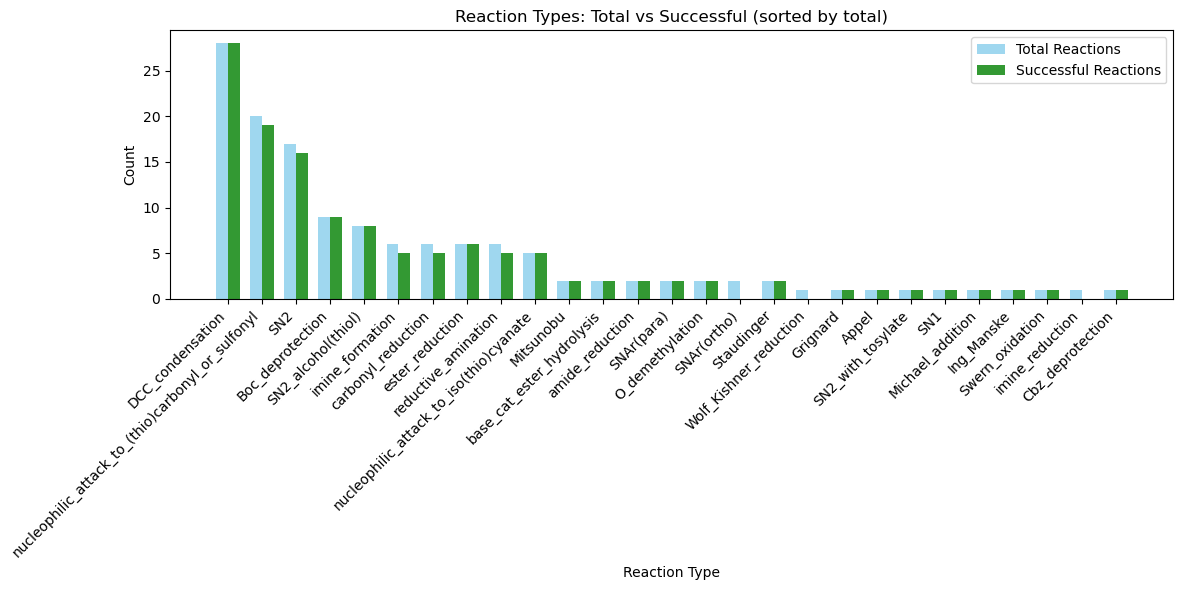

In [50]:
import matplotlib.pyplot as plt

# Extract and sort by total descending
categories = list(reaction_types.keys())
total = [reaction_types[cat][0] for cat in categories]
successful = [reaction_types[cat][1] for cat in categories]

pairs = sorted(zip(categories, total, successful), key=lambda t: t[1], reverse=True)
if pairs:
    categories_sorted, total_sorted, successful_sorted = zip(*pairs)
else:
    categories_sorted, total_sorted, successful_sorted = [], [], []

# Create bar chart
fig, ax = plt.subplots(figsize=(12, 6))
x = range(len(categories_sorted))
width = 0.35

bars1 = ax.bar([i - width/2 for i in x], total_sorted, width, label='Total Reactions', color='skyblue', alpha=0.8)
bars2 = ax.bar([i + width/2 for i in x], successful_sorted, width, label='Successful Reactions', color='green', alpha=0.8)

ax.set_xlabel('Reaction Type')
ax.set_ylabel('Count')
ax.set_title('Reaction Types: Total vs Successful (sorted by total)')
ax.set_xticks(x)
ax.set_xticklabels(categories_sorted, rotation=45, ha='right')
ax.legend()
plt.tight_layout()
plt.show()
# plt.savefig('plots/reaction_types_comparison_sorted.png', dpi=600)

In [51]:
print(set(all_indices) - set(success_indices) - set(failed_indices))

{11738, 3363, 29471}


In [52]:
print("Successful reaction indices:", success_indices)
print("Failed reaction indices:", failed_indices)
print("Others:")
print("Percentage success", len(success_indices)/(len(success_indices)+len(failed_indices))*100)
print("Unique mechanisms found:", unique_mechs)
print("Test set mechanisms found:", test_set_mechs)
print("Percentage of recall from training data:", test_set_mechs/(unique_mechs+test_set_mechs)*100)

Successful reaction indices: [1207, 4301, 4889, 5318, 8504, 9071, 11294, 11470, 12628, 14756, 16175, 17124, 18019, 18980, 19894, 20853, 21375, 22314, 23370, 24588, 25650, 28122, 29016, 31284, 527, 1990, 4449, 4954, 5410, 5749, 7529, 9114, 198, 359, 3285, 272, 838, 4513, 5328, 6285, 7334, 7573, 8779, 9169, 9200, 11059, 11558, 11696, 13343, 16769, 16949, 19695, 20212, 20811, 20960, 25718, 26218, 28943, 29603, 30421, 560, 1796, 2050, 2430, 4872, 5068, 8631, 10116, 12748, 13752, 16668, 17981, 19873, 21809, 24600, 24868, 27710, 27820, 28513, 29747, 29821, 699, 4054, 5779, 6325, 7919, 8363, 8913, 9108, 14445, 15796, 16510, 17410, 20899, 22663, 22761, 23560, 23583, 23774, 25572, 26220, 26571, 27575, 1652, 2172, 2756, 3587, 3757, 4094, 4988, 11214, 11274, 11760, 13279, 14620, 16909, 17430, 18429, 18825, 18856, 23283, 25769, 26838, 27900, 28125, 31318]
Failed reaction indices: [2015, 12165, 13617, 22417, 31343, 15431, 25569, 11931, 29112]
Others:
Percentage success 93.33333333333333
Unique mech

In [54]:


# Extract reaction type and get all failed indices for that type
rxn_type_current = rows[idx-1][2]
print(f"\nReaction type: {rxn_type_current}")

# Get all failed indices for each reaction type
for rxn_type_key in reaction_types.keys():
    failed_indices_by_type = []
    row = 0
    with open("mech-USPTO-31k.csv", 'r') as f:
        reader = csv.reader(f)
        for l in reader:
            row += 1
            if row in failed_indices and l[2] == rxn_type_key:
                failed_indices_by_type.append(row)
    
    print(f"Failed indices for {rxn_type_key}: {failed_indices_by_type}")
    


Reaction type: reductive_amination
Failed indices for SN2_alcohol(thiol): []
Failed indices for Wolf_Kishner_reduction: [2015]
Failed indices for Mitsunobu: []
Failed indices for nucleophilic_attack_to_(thio)carbonyl_or_sulfonyl: [31343]
Failed indices for Grignard: []
Failed indices for Boc_deprotection: []
Failed indices for SN2: [12165]
Failed indices for base_cat_ester_hydrolysis: []
Failed indices for imine_formation: [22417]
Failed indices for carbonyl_reduction: [11931]
Failed indices for Appel: []
Failed indices for DCC_condensation: []
Failed indices for amide_reduction: []
Failed indices for SNAr(para): []
Failed indices for SN2_with_tosylate: []
Failed indices for SN1: []
Failed indices for ester_reduction: []
Failed indices for reductive_amination: [29112]
Failed indices for Michael_addition: []
Failed indices for nucleophilic_attack_to_iso(thio)cyanate: []
Failed indices for Ing_Manske: []
Failed indices for O_demethylation: []
Failed indices for SNAr(ortho): [13617, 2556

In [ ]:
from IPython.display import display
from ipywidgets import Button, Output, VBox, HBox, Dropdown, HTML
import pandas as pd
import csv
from rdkit import Chem

# Load the CSV file
with open("mech-USPTO-31k.csv", 'r') as f:
    reader = csv.reader(f)
    rows = list(reader)

# Create interactive viewer
current_idx = {'value': 0}
failed_to_show = failed_indices.copy()

reasons = {}

output_display = Output()
reason_input = Dropdown(
    options=[('Select reason...', ''), ('not possible', 'not possible'), ('fixed', 'fixed'),
            ('need more steps', 'need more steps'), ('stereochemistry', 'stereochemistry'),
            ('stoichiometry', 'stoichiometry'), ('retrain', 'retrain'), ('filtered', 'filtered'), ('other', 'other')],
    value=''
)

def show_reaction(idx):
    with output_display:
        output_display.clear_output()
        if idx >= len(failed_to_show):
            print("No more reactions to review")
            return

        row_num = failed_to_show[idx] - 1
        rxn = rows[row_num][1].split('>>')
        sm = Chem.MolFromSmiles(rxn[0])
        prod = Chem.MolFromSmiles(rxn[1])

        for atom in sm.GetAtoms():
            atom.SetAtomMapNum(0)
        for atom in prod.GetAtoms():
            atom.SetAtomMapNum(0)

        print(f"Reaction {idx + 1}/{len(failed_to_show)} - Row: {row_num + 1}")
        print(f"Type: {rows[row_num][2]}")
        print(f"SMILES: {Chem.MolToSmiles(sm)} >> {Chem.MolToSmiles(prod)}")
        display(Chem.Draw.MolToImage(sm))
        display(Chem.Draw.MolToImage(prod))

def on_next(b):
    current_idx['value'] += 1
    reason_input.value = ''
    show_reaction(current_idx['value'])

def on_prev(b):
    current_idx['value'] = max(0, current_idx['value'] - 1)
    reason_input.value = ''
    show_reaction(current_idx['value'])

def on_save(b):
    if current_idx['value'] < len(failed_to_show) and reason_input.value:
        reasons[failed_to_show[current_idx['value']]] = reason_input.value
        print(f"Saved reason: {reason_input.value}")

prev_btn = Button(description='Previous')
next_btn = Button(description='Next')
save_btn = Button(description='Save Reason')

prev_btn.on_click(on_prev)
next_btn.on_click(on_next)
save_btn.on_click(on_save)

show_reaction(0)
display(VBox([output_display, reason_input, HBox([prev_btn, save_btn, next_btn])]))

In [ ]:
# reorganise reasons -> rows
reason_to_rows = {}
for row, reason in reasons.items():
    reason_to_rows.setdefault(reason, []).append(row)

# sort rows for each reason
for k in reason_to_rows:
    reason_to_rows[k].sort()

print(reason_to_rows)



{'not possible': [27063, 29433], 'fixed': [28653], 'need more steps': [730, 11249, 13287, 15205, 23156], 'filtered': [6027, 19960, 30636]}


In [ ]:
reason_to_rows = {'not possible': [27063, 29433], 'fixed': [28653], 'need more steps': [730, 11249, 13287, 15205, 23156], 'filtered': [6027, 19960, 30636]}


In [66]:
from ipywidgets import Output, Button, VBox, HBox, Checkbox, HTML
from IPython.display import display, HTML as DispHTML
import re
import os
import pickle
from rdkit.Chem import Draw


with open("mech-USPTO-31k.csv", 'r') as f:
    reader = csv.reader(f)
    rows = list(reader)

def _visualise_tree(node):
    mols = [Chem.MolFromSmiles(node.smiles)]
    while not node.is_root:
        node = node.parent
        mols.append(Chem.MolFromSmiles(node.smiles))
    mols.reverse()
    return Draw.MolsToGridImage(
        mols,
        molsPerRow=3,
        subImgSize=(400, 400),
        legends=[f"Mol {i}" for i in range(len(mols))],
    )


def _get_node_from_slurm(slurm_id):
    node = None
    for path in [
        f"old_slurm/slurm-{slurm_id}.out",
        f"slurm_out/slurm-{slurm_id}.out",
        f"slurm-{slurm_id}.out",
    ]:
        try:
            with open(path, "r") as f:
                lines = f.readlines()
            for line in lines:
                if "Running on master node:" in line:
                    node = line.split(":")[-1].split(".")[0].strip()
                    return node
        except Exception:
            continue
    return None


def _load_and_visualize_tree(slurm_id, node_dir_root="/nodescratch", row_id=None):
    node = _get_node_from_slurm(slurm_id)
    if node is None:
        raise RuntimeError(f"Could not find slurm output for {slurm_id}")

    node_dir = os.path.join(node_dir_root, node, "rd611", str(slurm_id))
    if not os.path.isdir(node_dir):
        raise RuntimeError(f"Node directory not found: {node_dir}")

    files = os.listdir(node_dir)
    if len(files) == 1:
        filename = files[0]
        pickle_path = os.path.join(node_dir, filename)
        with open(pickle_path, "rb") as file:
            node = pickle.load(file)
        image = _visualise_tree(node)
        return [image]

    out_images = []
    for filename in files:
        if filename.startswith(str(slurm_id)) and filename.endswith(".pkl"):
            parts = filename.split(".")[0].split("_")[1:]
            suffix = "_".join(parts) if parts else ""
            if suffix.split("_")[0] == str(row_id):
                pickle_path = os.path.join(node_dir, filename)
                with open(pickle_path, "rb") as file:
                    node = pickle.load(file)
                image = _visualise_tree(node)
                out_images.append((suffix, image))
    return out_images


def _find_slurm_for_row(row_id, search_dirs, pattern):
    row_id_str = str(row_id)
    row_re = re.compile(pattern.format(row_id=re.escape(row_id_str)))
    for d in search_dirs:
        if not os.path.isdir(d):
            continue
        for name in os.listdir(d):
            if not name.endswith(".out"):
                continue
            path = os.path.join(d, name)
            try:
                with open(path, "r", errors="ignore") as f:
                    text = f.read()
                if row_re.search(text):
                    # slurm-XXXXX.out
                    base = os.path.basename(name)
                    try:
                        slurm_id = int(base.split("-")[1].split(".")[0])
                        return slurm_id
                    except Exception:
                        continue
            except Exception:
                continue
    return None


def make_success_viewer_by_row(
    row_ids,
    search_dirs=None,
    row_pattern=r"\\b{row_id}\\b",
    node_dir_root="/nodescratch",
):
    """
    row_pattern is a regex template containing {row_id}. Default matches the
    row number as a standalone token. If your logs contain "Row: <id>",
    consider row_pattern=r"Row:\\s*{row_id}\\b".
    """

    if search_dirs is None:
        search_dirs = ["slurm_out", "old_slurm", "."]

    current_idx = {"value": 0}
    current_row = {"value": None}
    output_display = Output()
    status = HTML()
    ratings = {}  # row_id -> "good", "bad", or None
    ignore_chk = {"value": False}

    good_chk = Checkbox(description="Good", value=False)
    bad_chk = Checkbox(description="Bad", value=False)

    def show_success(idx):
        with output_display:
            output_display.clear_output()
            if idx >= len(row_ids):
                print("No more reactions to review")
                return

            row_id = row_ids[idx]
            current_idx["value"] = idx
            current_row["value"] = row_id
            rxn = rows[row_id - 1][1].split('>>')
            sm = Chem.MolFromSmiles(rxn[0])
            prod = Chem.MolFromSmiles(rxn[1])

            for atom in sm.GetAtoms():
                atom.SetAtomMapNum(0)
            for atom in prod.GetAtoms():
                atom.SetAtomMapNum(0)
            status.value = f"<b>Success {idx + 1}/{len(row_ids)}</b> SMILES: {Chem.MolToSmiles(sm)} >> {Chem.MolToSmiles(prod)} <br> "
            slurm_id = _find_slurm_for_row(row_id, search_dirs, row_pattern)
            if slurm_id is None:
                print(f"No slurm output found containing row {row_id}")
                # update checkboxes to saved values or default
                ignore_chk["value"] = True
                rating = ratings.get(row_id)
                good_chk.value = rating == "good"
                bad_chk.value = rating == "bad"
                ignore_chk["value"] = False
                return

            try:
                images = _load_and_visualize_tree(
                    slurm_id, node_dir_root=node_dir_root, row_id=row_id
                )
            except Exception as e:
                print(f"Failed to visualize row {row_id} (slurm {slurm_id}): {e}")
                ignore_chk["value"] = True
                rating = ratings.get(row_id)
                good_chk.value = rating == "good"
                bad_chk.value = rating == "bad"
                ignore_chk["value"] = False
                return

            # set checkboxes to saved values (without triggering save)
            ignore_chk["value"] = True
            rating = ratings.get(row_id)
            good_chk.value = rating == "good"
            bad_chk.value = rating == "bad"
            ignore_chk["value"] = False

            # images can be list[Image] (single) or list[(suffix, Image)] (multi)
            if images and isinstance(images[0], tuple):
                for suffix, image in images:
                    label = f"SLURM {slurm_id} — {suffix}" if suffix else f"SLURM {slurm_id}"
                    display(DispHTML(f"<div>{label}</div>"))
                    display(image)
            else:
                for image in images:
                    display(DispHTML(f"<div>SLURM {slurm_id}</div>"))
                    display(image)

    def on_next(_):
        current_idx["value"] += 1
        show_success(current_idx["value"])

    def on_prev(_):
        current_idx["value"] = max(0, current_idx["value"] - 1)
        show_success(current_idx["value"])

    def on_good_change(change):
        if ignore_chk["value"]:
            return
        row = current_row["value"]
        if row is not None:
            if change["new"]:
                ratings[row] = "good"
                bad_chk.value = False
            else:
                if ratings.get(row) == "good":
                    ratings[row] = None

    def on_bad_change(change):
        if ignore_chk["value"]:
            return
        row = current_row["value"]
        if row is not None:
            if change["new"]:
                ratings[row] = "bad"
                good_chk.value = False
            else:
                if ratings.get(row) == "bad":
                    ratings[row] = None

    prev_btn = Button(description="Previous")
    next_btn = Button(description="Next")
    prev_btn.on_click(on_prev)
    next_btn.on_click(on_next)
    good_chk.observe(on_good_change, names="value")
    bad_chk.observe(on_bad_change, names="value")

    show_success(0)
    viewer = VBox([status, output_display, HBox([prev_btn, good_chk, bad_chk, next_btn])])
    viewer.ratings = ratings  # attach dict so caller can access saved ratings
    return viewer


__all__ = ["make_success_viewer_by_row"]


In [67]:
viewer = make_success_viewer_by_row(
    success_indices, search_dirs=["slurm_out"], row_pattern=r"Processing row\s*{row_id}\b",   # adjust if your logs differ
      node_dir_root="/nodescratch"
  )

display(viewer)

In [ ]:
print(viewer.ratings)

{}


{1207: 'good', 4301: 'good', 4889: 'good', 5318: 'good', 8504: 'good', 9071: 'good', 11294: 'bad', 11470: 'good', 12628: 'good', 14756: 'good', 16175: 'good', 17124: 'bad', 18019: 'good', 18980: 'good', 19894: 'bad', 20853: 'good', 22314: 'good', 23370: 'good', 24588: 'good', 25650: 'good', 28122: 'good', 29016: 'good', 31284: 'good', 527: 'good', 1990: 'bad', 4449: 'bad', 4954: 'good', 5410: 'bad', 5749: 'bad', 7529: 'good', 9114: 'good', 198: 'bad', 359: None, 3285: 'bad', 272: 'good', 838: 'bad', 4513: 'good', 5328: 'good', 6285: 'good', 7334: 'bad', 7573: 'bad', 8779: 'bad', 9169: 'good', 9200: 'good', 11059: 'bad', 11558: 'good', 11696: 'good', 13343: 'bad', 16769: 'good', 16949: 'good', 19695: 'bad', 20212: 'good', 20960: 'good', 25718: 'good', 26218: 'good', 28943: 'good'}


{11294: 'bad', 21375: 'bad', 22314: 'bad'}


In [ ]:
viewer.ratings

{2493: 'good',
 3657: 'bad',
 3678: 'good',
 4511: 'good',
 10509: 'good',
 10796: 'good',
 11712: 'good',
 12746: 'bad',
 14251: 'good',
 16999: 'good',
 17963: 'bad',
 20648: 'good',
 22081: 'good',
 22713: 'bad',
 23305: 'good',
 25820: 'good',
 26689: 'good',
 26881: 'good',
 27257: 'good',
 28062: 'bad',
 28598: 'bad',
 30798: 'good',
 15799: 'good',
 20332: 'good',
 25088: 'good',
 367: 'bad',
 6462: 'bad',
 7384: 'good',
 9410: 'good',
 10487: 'good',
 12285: 'bad',
 13935: 'good',
 14519: 'good',
 14936: 'good',
 15235: 'good',
 16074: 'good',
 16557: 'good',
 16735: 'good',
 19104: 'good',
 20459: 'good',
 20961: 'bad',
 22097: 'bad',
 23511: 'bad',
 26030: 'good',
 31152: 'good',
 1306: 'good',
 4370: 'bad',
 5570: 'good',
 5873: 'good',
 8264: 'good',
 8451: 'good',
 10334: 'good',
 10501: 'bad',
 10894: 'good',
 11038: 'good',
 15840: 'bad',
 15866: 'bad',
 16675: 'good',
 17616: 'good',
 18214: 'good',
 18496: 'good',
 20410: 'good',
 21647: 'good',
 24689: 'good',
 26810:

{2493: 'good',
 3657: 'bad',
 3678: 'good',
 4511: 'good',
 10509: 'good',
 10796: 'good',
 11712: 'good',
 12746: 'bad',
 14251: 'good',
 16999: 'good',
 17963: 'bad',
 20648: 'good',
 22081: 'good',
 22713: 'bad',
 23305: 'good',
 25820: 'good',
 26689: 'good',
 26881: 'good',
 27257: 'good',
 28062: 'bad',
 28598: 'bad',
 30798: 'good',
 15799: 'good',
 20332: 'good',
 25088: 'good',
 367: 'bad',
 6462: 'bad',
 7384: 'good',
 9410: 'good',
 10487: 'good',
 12285: 'bad',
 13935: 'good',
 14519: 'good',
 14936: 'good',
 15235: 'good',
 16074: 'good',
 16557: 'good',
 16735: 'good',
 19104: 'good',
 20459: 'good',
 20961: 'bad',
 22097: 'bad',
 23511: 'bad',
 26030: 'good',
 31152: 'good',
 1306: 'good',
 4370: 'bad',
 5570: 'good',
 5873: 'good',
 8264: 'good',
 8451: 'good',
 10334: 'good',
 10501: 'bad',
 10894: 'good',
 11038: 'good',
 15840: 'bad',
 15866: 'bad',
 16675: 'good',
 17616: 'good',
 18214: 'good',
 18496: 'good',
 20410: 'good',
 21647: 'good',
 24689: 'good',
 26810:

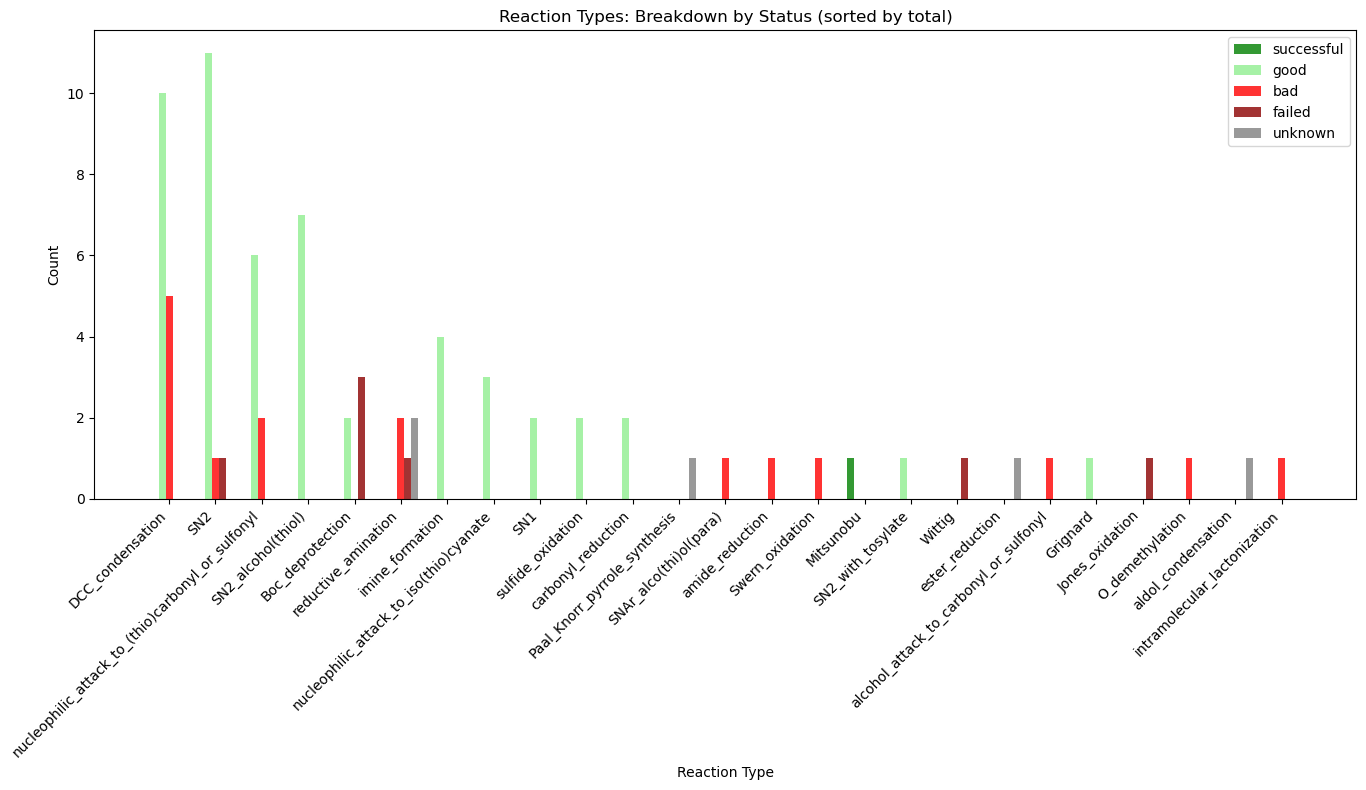

<Figure size 640x480 with 0 Axes>

In [ ]:
import matplotlib.pyplot as plt

# Assuming rows is loaded from 'mech-USPTO-31k.csv' as in previous cells
# If not already loaded, uncomment the following:
# with open('mech-USPTO-31k.csv', 'r') as f:
#     reader = csv.reader(f)
#     rows = list(reader)

# Initialize dict for counts per reaction type
type_to_counts = {}

# Get all unique reaction types from rows
all_types = set()
for row in rows:
    all_types.add(row[2])

for typ in all_types:
    type_to_counts[typ] = {'successful': 0, 'good': 0, 'failed_or_bad': 0, 'unknown': 0}

# Categorize successful reactions by type
for idx in success_indices:
    typ = rows[idx-1][2]
    if idx in viewer.ratings:
        rating = viewer.ratings[idx]
        if rating == 'good':
            type_to_counts[typ]['good'] += 1
        elif rating == 'bad':
            type_to_counts[typ]['failed_or_bad'] += 1
    else:
        type_to_counts[typ]['successful'] += 1

# Categorize failed reactions by type
for idx in failed_indices:
    typ = rows[idx-1][2]
    is_unknown = idx in reason_to_rows.get('need more steps', [])
    if is_unknown:
        type_to_counts[typ]['unknown'] += 1
    else:
        type_to_counts[typ]['failed_or_bad'] += 1

# Prepare data for plotting: sort types by total count descending, but only include types with total > 0
type_totals = {}
for typ, counts in type_to_counts.items():
    type_totals[typ] = sum(counts.values())

sorted_types = [typ for typ in sorted(type_totals, key=type_totals.get, reverse=True) if type_totals[typ] > 0]

# Categories for bars
categories = ['successful', 'good', 'failed_or_bad', 'unknown']
colors = ['green', 'lightgreen', 'red', 'gray']

# Create grouped bar chart
fig, ax = plt.subplots(figsize=(14, 8))
x = range(len(sorted_types))
width = 0.15  # Adjust width for multiple bars

for i, cat in enumerate(categories):
    values = [type_to_counts[typ][cat] for typ in sorted_types]
    ax.bar([pos + i * width for pos in x], values, width, label=cat, color=colors[i], alpha=0.8)

ax.set_xlabel('Reaction Type')
ax.set_ylabel('Count')
ax.set_title('Reaction Types: Breakdown by Status (sorted by total)')
ax.set_xticks([pos + width * (len(categories) - 1) / 2 for pos in x])
ax.set_xticklabels(sorted_types, rotation=45, ha='right')
ax.legend()
plt.tight_layout()
plt.show()
plt.savefig('plots/reaction_types_status_breakdown.png', dpi=600)

In [ ]:
len(success_indices) - len(viewer.ratings)

1

In [ ]:
for k,v in reasons.items():
    if v == 'need more steps':
        print(k)

13512
8572
10096
495
20516
2442
837


as a general rule  
Carbonyl reduction - stereochemistry  
Nitrile reduction - need more steps  
Ester reduction - need more steps  
Wittig - not possible  
Horner-Wadsworth-Emmons -not possible  
Appel - not possible  
Ing-Maske - need more steps

In [ ]:
import pandas as pd

# Create a dataframe from the reasons dictionary
results_df = pd.DataFrame(list(reasons.items()), columns=['Row_Index', 'Reason'])

# Save to CSV
results_df.to_csv('failure_reasons_2.csv', index=False)

print(f"Saved {len(results_df)} results to 'failure_reasons.csv'")

Saved 16 results to 'failure_reasons.csv'


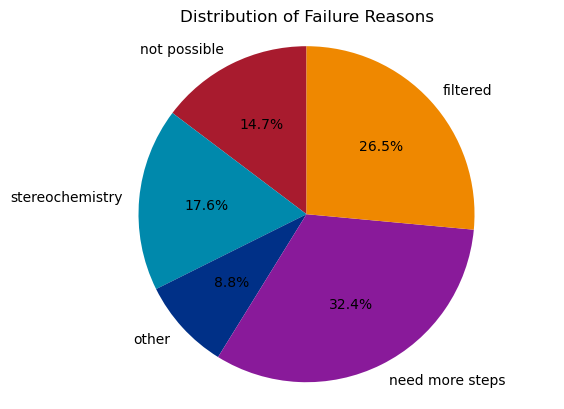

In [ ]:
from matplotlib.colors import ListedColormap
import matplotlib.pyplot as plt

custom_colors = [
    (169, 27, 46),  # blue-ish
    (0, 138, 173),  # red-ish
    (0, 48, 136),  # green-ish
    (138, 26, 155),  # yellow-ish
    (240, 137, 0)   # purple-ish
]

custom_c = [ tuple(c[i] / 256.0 for i in range(3)) for c in custom_colors ]

custom_cmap = ListedColormap(custom_c)

# Count the reasons
reason_counts = {}
for reason in reasons.values():
    reason_counts[reason] = reason_counts.get(reason, 0) + 1

# Create pie chart
labels = list(reason_counts.keys())
sizes = list(reason_counts.values())
fig, ax = plt.subplots()
ax.pie(sizes, labels=labels, autopct='%1.1f%%', startangle=90, colors=custom_c)
ax.axis('equal')  # Equal aspect ratio ensures that pie is drawn as a circle.
plt.title('Distribution of Failure Reasons')
plt.show()

In [ ]:
# Calculate true failures: only "not possible" and "filtered"
true_failures = sum(1 for reason in reasons.values() if reason in ["not possible", "filtered"])

# Total reactions
total_reactions = len(success_indices) + len(failed_indices)

# New failure rate
new_failure_rate = (true_failures / total_reactions) * 100 if total_reactions > 0 else 0

print(f"New success rate (only 'not possible' and 'filtered' as failures): {100 - new_failure_rate:.2f}%")

New success rate (only 'not possible' and 'filtered' as failures): 91.91%


In [ ]:
# Show all reactions labeled "other" or "filtered"
matches = [r for r, reason in reasons.items() if reason in ("other", "filtered")]

if not matches:
    print("No reactions labeled 'other' or 'filtered'.")
else:
    for row in sorted(matches):
        row_idx = row - 1
        rxn_line = rows[row_idx][1]
        parts = rxn_line.split(">>")
        react_smiles = parts[0].strip()
        prod_smiles = parts[1].strip() if len(parts) > 1 else ""
        sm = Chem.MolFromSmiles(react_smiles)
        prod = Chem.MolFromSmiles(prod_smiles) if prod_smiles else None
        if sm:
            for a in sm.GetAtoms():
                a.SetAtomMapNum(0)
        if prod:
            for a in prod.GetAtoms():
                a.SetAtomMapNum(0)
        print(f"Row {row} | Type: {rows[row_idx][2]} | Reason: {reasons[row]}")
        print(f"SMILES: {react_smiles} >> {prod_smiles}")
        display(Chem.Draw.MolToImage(sm))
        if prod:
            display(Chem.Draw.MolToImage(prod))

In [ ]:
with open("mech-USPTO-31k.csv", 'r') as f:
    reader = csv.reader(f)
    row = 0
    for l in reader:
        row += 1
        if row not in failed_indices:
            continue
        print("_"*40)
        print(f"Processing row {row}")
        print(l[1])
        print(f"Reaction type: {l[2]}")
        line = l[1]
        l_s = line.split(">>")
        reactant = l_s[0].strip()
        product = l_s[1].strip()
        try:
            run_parallel(reactant, product, str(row))
        except Exception as e:
            print(e)